# Notebook 02 — CNN fault classifier (PyTorch)

In Notebook 01 **we** designed the features (hot blobs, thirds, HOG). A **Convolutional Neural Network (CNN)** learns its own features directly from the pixels.
Same data, **same split (`splits.csv`)**, same metric (macro-F1), so the two results can be compared fairly.

Baseline to beat (Notebook 01, Gradient Boosting): **test macro-F1 = 0.521, accuracy = 0.690**.

### Before you run
1. Run Notebook 01 first (it creates `splits.csv`).
2. Install PyTorch (see the setup guide). This notebook picks the fastest device automatically: NVIDIA GPU (`cuda`), Apple-Silicon GPU (`mps`), or CPU.
3. Expected time: a few minutes on a GPU; about 10–20 minutes on a laptop CPU (the images are tiny).

### The 6 things every PyTorch training script has
| # | Piece | In this notebook |
|---|---|---|
| 1 | **Dataset** | a class that returns *one* (image, label) pair |
| 2 | **DataLoader** | groups samples into **batches** and shuffles them |
| 3 | **Model** | the network (`nn.Module`) |
| 4 | **Loss function** | measures how wrong the predictions are (cross-entropy) |
| 5 | **Optimizer** | changes the weights to reduce the loss (Adam) |
| 6 | **Training loop** | repeat: predict → loss → `backward()` → `step()` |

Once you understand these six, you can read almost any PyTorch project.

## 0. Imports and device
A **tensor** is PyTorch's version of a NumPy array, but it can live on the GPU and it remembers how it was computed (so gradients can be calculated automatically).

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DATA_DIR = Path("archive/2020-02-14_InfraredSolarModules/InfraredSolarModules")

if torch.cuda.is_available():
    device = torch.device("cuda")          # NVIDIA GPU (lab server)
elif torch.backends.mps.is_available():
    device = torch.device("mps")           # Apple-Silicon Mac GPU
else:
    device = torch.device("cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.0 | device: mps


## 1. Load the split from Notebook 01
The class names are turned into integers 0–11 because the network outputs 12 numbers, one per class.

In [2]:
split = pd.read_csv("splits.csv")
CLASSES = sorted(split.label.unique())
cls2idx = {c: i for i, c in enumerate(CLASSES)}
split["y"] = split.label.map(cls2idx)
train_df, val_df, test_df = [split[split.split == s].reset_index(drop=True) for s in ("train", "val", "test")]
print(len(train_df), len(val_df), len(test_df))
print(dict(enumerate(CLASSES)))

14000 3000 3000
{0: 'Cell', 1: 'Cell-Multi', 2: 'Cracking', 3: 'Diode', 4: 'Diode-Multi', 5: 'Hot-Spot', 6: 'Hot-Spot-Multi', 7: 'No-Anomaly', 8: 'Offline-Module', 9: 'Shadowing', 10: 'Soiling', 11: 'Vegetation'}


## 2. Dataset: how to get one sample
A PyTorch `Dataset` needs only two methods:
* `__len__`: how many samples there are
* `__getitem__(i)`: return sample *i* as `(image_tensor, label)`

**Preprocessing** is the same per-image normalisation as Notebook 01: `(img − median) / std`, i.e. "how much hotter than the rest of the module".

**Data augmentation** (training set only): random horizontal and vertical flips. A module flipped left-right still has the same fault, so this creates "new" examples for free and helps the rare classes. We do **not** rotate by 90°, because the image is 40 × 24 (not square) and the substring direction matters.

To make it fast, all 20,000 tiny images are loaded into memory once.

In [3]:
def load_all(d):
    imgs = np.stack([np.asarray(Image.open(DATA_DIR / p), dtype=np.float32) / 255.0 for p in d.path])
    med = np.median(imgs, axis=(1, 2), keepdims=True)
    std = imgs.std(axis=(1, 2), keepdims=True) + 1e-6
    return (imgs - med) / std                           # shape (N, 40, 24)

class IRModules(Dataset):
    def __init__(self, d, augment=False):
        self.x = torch.from_numpy(load_all(d)).unsqueeze(1)   # (N, 1, 40, 24): 1 = one channel (gray)
        self.y = torch.from_numpy(d.y.values).long()
        self.augment = augment
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = self.x[i]
        if self.augment:
            if torch.rand(1) < 0.5: x = torch.flip(x, dims=[2])   # left-right
            if torch.rand(1) < 0.5: x = torch.flip(x, dims=[1])   # up-down
        return x, self.y[i]

train_ds, val_ds, test_ds = IRModules(train_df, augment=True), IRModules(val_df), IRModules(test_df)
x0, y0 = train_ds[0]
print("one sample:", x0.shape, "label:", y0.item(), CLASSES[y0])

/var/folders/cy/g3jpxcd168x1c4wy7wzgdkb00000gn/T/ipykernel_28433/2057503783.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  self.y = torch.from_numpy(d.y.values).long()


one sample: torch.Size([1, 40, 24]) label: 8 Offline-Module


## 3. DataLoader: batches
The network is trained on **batches** of 128 images at a time (faster than one by one, more stable than all at once).
`shuffle=True` for training so every epoch sees the images in a different order.

In [4]:
BATCH = 128
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(val_ds,   batch_size=512)
test_dl  = DataLoader(test_ds,  batch_size=512)
xb, yb = next(iter(train_dl))
print("one batch:", xb.shape, yb.shape)

one batch: torch.Size([128, 1, 40, 24]) torch.Size([128])


## 4. The model: a small CNN
**Convolution** (`Conv2d`): a small 3 × 3 filter slides over the image and responds to a local pattern (edge, hot dot, strip). The network learns the filter values itself.
**BatchNorm** keeps numbers in a good range (faster, more stable training). **ReLU** = `max(0, x)`, the non-linearity.
**MaxPool** halves the image size, so deeper layers see larger regions of the module.

```
input 1×40×24
 → [Conv 32 → BN → ReLU] ×2 → MaxPool → 32×20×12     (small patterns: single hot cell)
 → [Conv 64 → BN → ReLU] ×2 → MaxPool → 64×10×6      (medium: groups of cells)
 → [Conv 128 → BN → ReLU] ×2 → MaxPool → 128×5×3     (large: one third of the module, whole module)
 → Flatten (1920) → Dropout → Linear 256 → ReLU → Dropout → Linear 12   (one score per class)
```
We keep the 5 × 3 spatial map (instead of averaging it away) because **where** the heat is matters (e.g. which third for Diode).
**Dropout** randomly switches off neurons during training, which reduces over-fitting.

In [5]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.MaxPool2d(2))

class SmallCNN(nn.Module):
    def __init__(self, n_classes=12):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 32), conv_block(32, 64), conv_block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(128 * 5 * 3, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

model = SmallCNN(len(CLASSES)).to(device)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    print("output shape for one batch:", model(xb.to(device)).shape)   # should be (128, 12)

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=

## 5. Loss and optimizer
**Cross-entropy loss** compares the 12 predicted scores with the true class.
**Class weights** fix the imbalance, as in Notebook 01: a class with few images gets a larger weight.
We use `(N / (K·n_c))^0.5` (the *square root* of the fully balanced weight). Full balancing gives `Diode-Multi` ~10× the weight of `No-Anomaly`, which often makes training unstable. The square root is a common compromise; you can try both and compare (a good experiment for your report).

**Adam** is the standard optimizer. `lr` (learning rate) = step size. The **cosine schedule** slowly lowers it so the model settles at the end.

In [6]:
counts = np.bincount(train_df.y, minlength=len(CLASSES))
w = (len(train_df) / (len(CLASSES) * counts)) ** 0.5
class_weights = torch.tensor(w, dtype=torch.float32, device=device)
for c, n, wi in zip(CLASSES, counts, w):
    print(f"{c:15s} n={n:5d}  weight={wi:.2f}")

EPOCHS = 40
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

Cell            n= 1313  weight=0.94
Cell-Multi      n=  902  weight=1.14
Cracking        n=  658  weight=1.33
Diode           n= 1049  weight=1.05
Diode-Multi     n=  123  weight=3.08
Hot-Spot        n=  175  weight=2.58
Hot-Spot-Multi  n=  172  weight=2.60
No-Anomaly      n= 7000  weight=0.41
Offline-Module  n=  579  weight=1.42
Shadowing       n=  740  weight=1.26
Soiling         n=  142  weight=2.87
Vegetation      n= 1147  weight=1.01


## 6. The training loop: the heart of deep learning
For every batch:
1. `optimizer.zero_grad()`: clear old gradients
2. `out = model(x)`: **forward pass**, compute predictions
3. `loss = criterion(out, y)`: how wrong?
4. `loss.backward()`: **back-propagation**, compute how each weight should change
5. `optimizer.step()`: update the weights

After each **epoch** (one pass over all training images) we measure macro-F1 on the **validation** set and keep the best model (so we don't keep a later, over-fitted one).
`model.train()` / `model.eval()` switch Dropout and BatchNorm between training and testing behaviour. **Forgetting `model.eval()` is a classic bug.**

In [7]:
def predict(model, dl):
    model.eval()
    preds, ys = [], []
    with torch.no_grad():                               # no gradients needed → faster, less memory
        for x, y in dl:
            preds.append(model(x.to(device)).argmax(1).cpu())
            ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(preds).numpy()

history, best_f1 = [], -1
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y)
    scheduler.step()

    yv, pv = predict(model, val_dl)
    f1 = f1_score(yv, pv, average="macro")
    history.append({"epoch": epoch, "train_loss": total / len(train_ds), "val_macroF1": f1,
                    "val_acc": accuracy_score(yv, pv)})
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), "best_cnn.pt")    # save the best weights
    print(f"epoch {epoch:2d} | loss {history[-1]['train_loss']:.3f} | val acc {history[-1]['val_acc']:.3f} "
          f"| val macro-F1 {f1:.3f} {'*' if f1 == best_f1 else ''} | {time.time()-t0:.0f}s")

epoch  1 | loss 1.986 | val acc 0.643 | val macro-F1 0.267 * | 7s
epoch  2 | loss 1.569 | val acc 0.648 | val macro-F1 0.368 * | 11s
epoch  3 | loss 1.433 | val acc 0.666 | val macro-F1 0.380 * | 15s
epoch  4 | loss 1.337 | val acc 0.684 | val macro-F1 0.433 * | 18s
epoch  5 | loss 1.283 | val acc 0.706 | val macro-F1 0.466 * | 22s
epoch  6 | loss 1.231 | val acc 0.702 | val macro-F1 0.501 * | 26s
epoch  7 | loss 1.195 | val acc 0.711 | val macro-F1 0.507 * | 29s
epoch  8 | loss 1.159 | val acc 0.731 | val macro-F1 0.545 * | 33s
epoch  9 | loss 1.137 | val acc 0.712 | val macro-F1 0.523  | 36s
epoch 10 | loss 1.099 | val acc 0.694 | val macro-F1 0.540  | 40s
epoch 11 | loss 1.077 | val acc 0.717 | val macro-F1 0.545  | 44s
epoch 12 | loss 1.038 | val acc 0.621 | val macro-F1 0.488  | 47s
epoch 13 | loss 1.019 | val acc 0.720 | val macro-F1 0.555 * | 51s
epoch 14 | loss 1.008 | val acc 0.666 | val macro-F1 0.540  | 55s
epoch 15 | loss 0.976 | val acc 0.758 | val macro-F1 0.595 * | 58s
e

## 7. Learning curves
* Training loss should go **down**.
* Validation macro-F1 should go **up** and then flatten. If it goes down while training loss still falls, the model is **over-fitting** (memorising the training images).

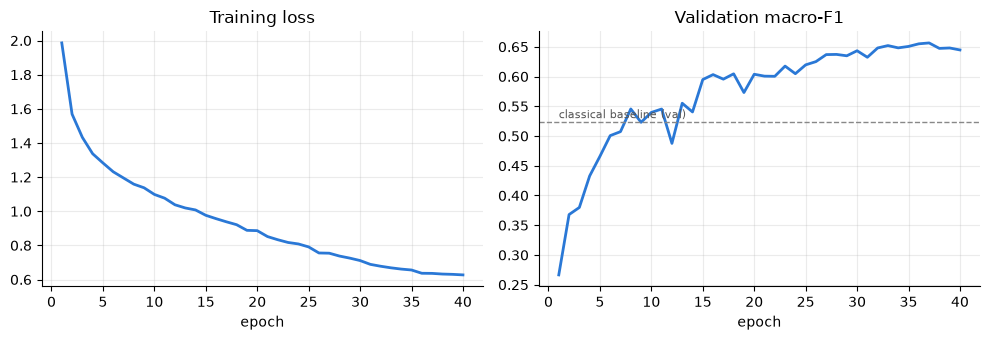

In [8]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.epoch, h.train_loss, color="#2a78d6", lw=2); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h.epoch, h.val_macroF1, color="#2a78d6", lw=2); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch")
ax[1].axhline(0.524, color="#888", ls="--", lw=1); ax[1].text(1, 0.53, "classical baseline (val)", fontsize=8, color="#555")
for a in ax: a.grid(alpha=0.25); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_cnn_learning_curves.png", dpi=200); plt.show()

## 8. Final test evaluation (once, with the best saved model)

CNN TEST accuracy = 0.794   macro-F1 = 0.659
Classical baseline: accuracy = 0.690   macro-F1 = 0.521

                precision    recall  f1-score   support

          Cell      0.600     0.713     0.652       282
    Cell-Multi      0.543     0.394     0.456       193
      Cracking      0.669     0.674     0.671       141
         Diode      0.955     0.947     0.951       225
   Diode-Multi      0.920     0.885     0.902        26
      Hot-Spot      0.579     0.595     0.587        37
Hot-Spot-Multi      0.500     0.595     0.543        37
    No-Anomaly      0.923     0.921     0.922      1500
Offline-Module      0.555     0.613     0.582       124
     Shadowing      0.686     0.665     0.675       158
       Soiling      0.333     0.290     0.310        31
    Vegetation      0.661     0.642     0.652       246

      accuracy                          0.794      3000
     macro avg      0.660     0.661     0.659      3000
  weighted avg      0.794     0.794     0.792      3000


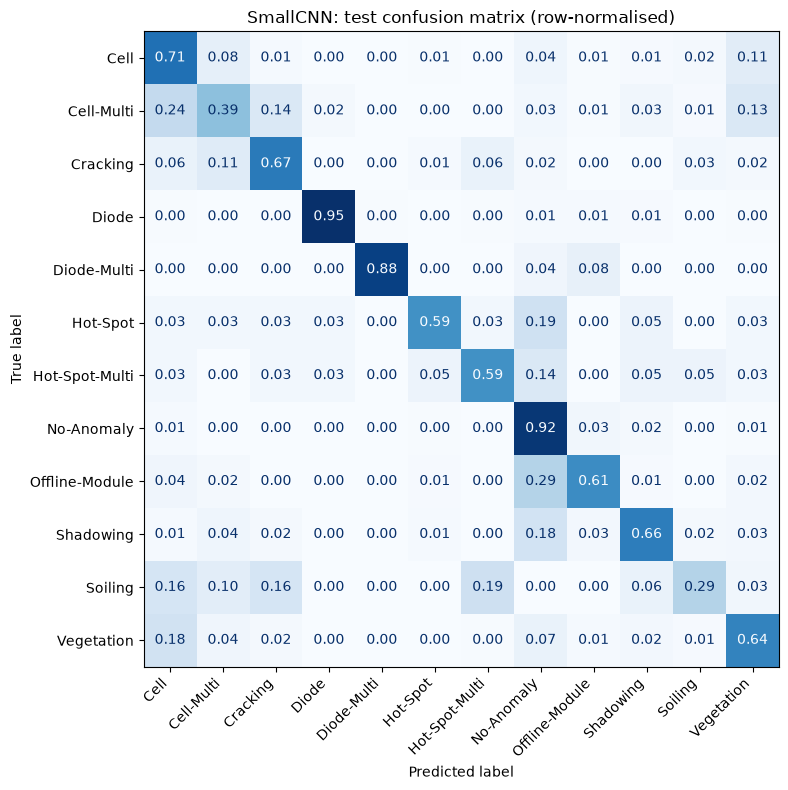

              precision    recall  f1-score   support

       Fault      0.921     0.923     0.922      1500
          OK      0.923     0.921     0.922      1500

    accuracy                          0.922      3000
   macro avg      0.922     0.922     0.922      3000
weighted avg      0.922     0.922     0.922      3000



In [9]:
model.load_state_dict(torch.load("best_cnn.pt", map_location=device))
yt, pt = predict(model, test_dl)
print(f"CNN TEST accuracy = {accuracy_score(yt, pt):.3f}   macro-F1 = {f1_score(yt, pt, average='macro'):.3f}")
print("Classical baseline: accuracy = 0.690   macro-F1 = 0.521\n")
print(classification_report(yt, pt, target_names=CLASSES, digits=3))

cm = confusion_matrix(yt, pt, normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
plt.xticks(rotation=45, ha="right"); ax.set_title("SmallCNN: test confusion matrix (row-normalised)")
plt.tight_layout(); plt.savefig("fig_cnn_confusion_matrix.png", dpi=200); plt.show()

yb_t = np.where(np.array(CLASSES)[yt] == "No-Anomaly", "OK", "Fault")
yb_p = np.where(np.array(CLASSES)[pt] == "No-Anomaly", "OK", "Fault")
print(classification_report(yb_t, yb_p, digits=3))

## 9. Experiments to try next (one change at a time, record each result in a table)
1. Full class weights (remove `** 0.5`) vs square-root weights vs no weights.
2. More epochs (60) or a smaller learning rate (3e-4).
3. A pretrained **ResNet-18** from `torchvision.models` (resize images to 64 × 128 or larger, repeat the gray channel 3 times). Transfer learning usually helps when data is small.
4. Merge rare classes (e.g. Hot-Spot + Hot-Spot-Multi) and report both versions.

Keep a table like: `experiment | val macro-F1 | test macro-F1 | notes`. That table becomes a results section of your report.